# A third depth for the RHM sampling law, in 1D -- 2026-11-03

**What was tested.** The measured 2D law is `P* = 0.21 |R_L| = exp(Theta(n))`, where `P` is the
number of training samples and `P*` is where the LS machine's output is most often **both novel
and fully grammatical** (hshunt's success criterion). That law was fitted over only *two* depths,
`L = 2` and `L = 3`, because the window that just reaches the root has side
`k = 2 s^(L-1) - 1 = d - 1`, and at `L = 4` in 2D that is a `15 x 15 = 225`-site patch: the table
never fills and the base-`(v+1)` `int64` window code overflows.

**Why 1D fixes that.** In 1D the same root-reaching window is 15 *sites*, not 225. So `n = 4, 8,
16` are all measurable and the lever arm triples -- the cheapest honest test of the asymptotics
available.

**Result, in two parts.**

1. **`P* = exp(Theta(n))` is confirmed at a third depth.** `ln P*` grows 0.374 per site over
   `n = 4..16`.
2. **`P* = 0.21 |R_L|` does not carry outside 2D.** The free exponent is `b = 0.689 +- 0.045`
   (robust), 6.8 sd below 1, against 2D's `0.965 +- 0.041`. The matched-`n` control is decisive:
   1D at `L=4` and 2D at `L=2` both have `n = 16` sites, and give `x* = 0.050` vs `0.193` -- 3.9x
   apart -- while 2D itself is flat in `n` (0.193 at `n=16`, 0.207 at `n=64`). So the fall is not
   a function of `n`. **The constant 0.21 is a 2D number.**

### Tokenization

The 1D RHM is implemented in `scripts/rhm_1d_depth.py` (`RHM1D`), mirroring
`RandomHierarchyModel2D`'s conventions exactly so the comparison is not confounded. A sample is a
string of `d = s**L` **sites**, each site one token from an alphabet of `v` symbols (`0 .. v-1`).
A token *is* an integer label -- no sub-token structure, no embedding. Generation starts from a
root symbol uniform on `{0, ..., v-1}` and applies `L` levels of production rules, each expanding
one symbol into `s` symbols drawn from `m` synonymous right-hand sides (`rules[l]` has shape
`(v, m, s)`, drawn i.i.d. **with replacement**, so words collide and the realized `|R_L|` varies
widely between rule seeds -- which is what gives the collapse test its range).

The LS machine never sees the tree. It sees length-`k` windows cut from the leaf string: for a
masked site it returns the empirical distribution of the **centre** tokens of every training
window agreeing on all observed sites, Laplace-smoothed with `alpha = 1e-3`. Off-grid sites get
their own marker symbol `v` and count as *observed*, so a border window can only match training
windows framed the same way. Windows are packed base `v+1` into one `int64` for counting; in 1D
that is `k` digits rather than `k*k`, which is exactly why `L = 4` is reachable here.

## 0. Provenance

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

print('commit  ', subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=ROOT,
                                 capture_output=True, text=True).stdout.strip())
print('sweep   ', 'scripts/rhm_1d_depth.py, Slurm job 51009204 (sganguli, 1 GPU)')
print('analysis', 'scripts/rhm_1d_analysis.py')
print('config  ', 's=2, v in {2,3,4}, m in {2..6}, L in {2,3,4}, k = 2*s^(L-1)-1 = d-1,')
print('        ', 'rule_seeds 0..2 (model seed 1000+rs), n_gen 2048, alpha_smooth 1e-3,')
print('        ', 'P ladder 1,2,4,...,262144 (19 rungs), R_max 1.5e5')
print('seeds   ', 'training sample seed 1234+7*rs; generator seed = that +9973')

SW = ROOT / 'results/rhm_1d/2026-11-03'
rows  = json.load(open(SW / 'sweep.json'))
peaks = json.load(open(SW / 'peaks.json'))
RLj   = json.load(open(SW / 'RL_exact_1d.json'))
RL = {(r['v'], r['m'], r['s'], r['L'], r['rule_seed']): r['R_L'] for r in RLj}
p2 = json.load(open(ROOT / 'results/rhm_sampling/2026-11-03/peak_summary.json'))
br = [p for p in peaks if p['bracketed']]
print('\n%d rows, %d cells, %d bracketed, %d 2D cells for comparison'
      % (len(rows), len(peaks), len(br), len(p2)))

commit   ce80ae4
sweep    scripts/rhm_1d_depth.py, Slurm job 51009204 (sganguli, 1 GPU)
analysis scripts/rhm_1d_analysis.py
config   s=2, v in {2,3,4}, m in {2..6}, L in {2,3,4}, k = 2*s^(L-1)-1 = d-1,
         rule_seeds 0..2 (model seed 1000+rs), n_gen 2048, alpha_smooth 1e-3,
         P ladder 1,2,4,...,262144 (19 rungs), R_max 1.5e5
seeds    training sample seed 1234+7*rs; generator seed = that +9973

2147 rows, 113 cells, 110 bracketed, 33 2D cells for comparison


## 1. Metrics table

`x* = P*/|R_L|`, with `P*` from a log-`P` parabola through the top three ladder points and
reported **only when the argmax is interior** -- an unbracketed peak is a bound, not a value, and
those cells are excluded rather than clamped to the ladder edge. `|R_L|` is enumerated exactly
(`exact_RL`), never taken from the nominal `v m^M`, because the collisions are the point.

In [2]:
print('%-3s %-4s %-3s %-3s %-6s %-18s %-18s %-9s %-9s'
      % ('L', 'n', 'k', 'v', 'cells', '|R_L| range', 'P* range', 'med x*', 'med succ'))
print('-' * 86)
for L in sorted({p['L'] for p in br}):
    for v in sorted({p['v'] for p in br if p['L'] == L}):
        sel = [p for p in br if p['L'] == L and p['v'] == v]
        R  = [p['R_L'] for p in sel]
        Ps = [p['P_star'] for p in sel]
        print('%-3d %-4d %-3d %-3d %-6d %-18s %-18s %-9.3f %-9.3f'
              % (L, 2**L, sel[0]['k'], v, len(sel),
                 '%d-%d' % (min(R), max(R)), '%.0f-%.0f' % (min(Ps), max(Ps)),
                 np.median([p['ratio'] for p in sel]),
                 np.median([p['succ_max'] for p in sel])))

print('\nexcluded (peak at the ladder edge, not bracketed): %d of %d cells'
      % (len(peaks) - len(br), len(peaks)))

L   n    k   v   cells  |R_L| range        P* range           med x*    med succ 
--------------------------------------------------------------------------------------
2   4    3   2   12     4-16               2-8                0.196     0.548    
2   4    3   3   15     12-64              2-18               0.166     0.428    
2   4    3   4   15     22-192             2-17               0.118     0.446    
3   8    7   2   15     36-256             2-23               0.091     0.509    
3   8    7   3   15     176-6400           15-123             0.066     0.451    
3   8    7   4   15     208-24298          22-576             0.043     0.499    
4   16   15  2   15     2304-65536         102-592            0.026     0.565    
4   16   15  3   5      1429-65480         158-4821           0.092     0.389    
4   16   15  4   3      11130-90368        2182-11499         0.127     0.338    

excluded (peak at the ladder edge, not bracketed): 3 of 113 cells


## 2. The exponent, and the artefact it has to survive

`b < 1` is the whole claim, so it must not be manufactured by the ladder. `P` is an integer on a
2x ladder, so a cell peaking at `P* = 2` has nowhere to go: at `L = 2` (`n = 4`) `|R_L|` spans 48x
but `P*` only 11x, and every `P*` lies in `2..18` -- about four rungs. Dropping those cells (and
the whole `n = 4` depth) is the honest check.

In [3]:
def fit(sel, lab):
    if len(sel) < 4:
        return
    lR = np.log([p['R_L'] for p in sel]); lP = np.log([p['P_star'] for p in sel])
    b, a = np.polyfit(lR, lP, 1)
    res = lP - (b * lR + a)
    se = float(np.sqrt((res**2).sum() / (len(lR) - 2) / ((lR - lR.mean())**2).sum()))
    print('  %-20s n=%-4d b = %.3f +- %.3f   (1 is %4.1f sd away)   e^a = %.3f'
          % (lab, len(sel), b, se, abs(b - 1) / se, np.exp(a)))

for L in sorted({p['L'] for p in br}):
    fit([p for p in br if p['L'] == L], '1D L=%d (n=%d)' % (L, 2**L))
fit(br, '1D pooled')
rob = [p for p in br if p['P_star'] >= 8 and p['L'] >= 3]
fit(rob, '1D robust (P*>=8)')
print('  %-20s n=%-4d b = %.3f +- %.3f   (1 is %4.1f sd away)'
      % ('2D pooled [previous]', len([p for p in p2 if p['bracketed']]),
         0.965, 0.041, abs(0.965 - 1) / 0.041))

  1D L=2 (n=4)         n=42   b = 0.283 +- 0.121   (1 is  5.9 sd away)   e^a = 2.002
  1D L=3 (n=8)         n=45   b = 0.708 +- 0.055   (1 is  5.3 sd away)   e^a = 0.433
  1D L=4 (n=16)        n=23   b = 0.579 +- 0.171   (1 is  2.5 sd away)   e^a = 1.970
  1D pooled            n=110  b = 0.708 +- 0.028   (1 is 10.4 sd away)   e^a = 0.469
  1D robust (P*>=8)    n=64   b = 0.689 +- 0.045   (1 is  6.8 sd away)   e^a = 0.594
  2D pooled [previous] n=30   b = 0.965 +- 0.041   (1 is  0.9 sd away)


## 3. The matched-`n` control

This is what makes the result interpretable, and it is the reason the first reading of the data
("`x*` drifts with depth") was wrong. 1D at `L = 4` and 2D at `L = 2` have the **same number of
sites**. If `x*` were a function of `n` they would have to agree.

In [4]:
pts  = [(1, 2**p['L'], p['ratio']) for p in br]
pts += [(2, p['s']**(2*p['L']), p['ratio']) for p in p2 if p['bracketed']]

print('%-5s %-5s %-6s %-10s %s' % ('dim', 'n', 'cells', 'median x*', 'geo sd'))
for dim, n in sorted({(d, n) for d, n, _ in pts}):
    x = [r for d, nn, r in pts if d == dim and nn == n]
    print('%-4dD %-5d %-6d %-10.3f %.2fx'
          % (dim, n, len(x), np.median(x), np.exp(np.std(np.log(x), ddof=1))))

a16 = np.median([r for d, n, r in pts if d == 1 and n == 16])
b16 = np.median([r for d, n, r in pts if d == 2 and n == 16])
n2  = sorted({n for d, n, _ in pts if d == 2})
lo  = np.median([r for d, n, r in pts if d == 2 and n == n2[0]])
hi  = np.median([r for d, n, r in pts if d == 2 and n == n2[-1]])
print('\nat n=16:  1D %.3f  vs  2D %.3f   -> %.2fx apart' % (a16, b16, max(a16,b16)/min(a16,b16)))
print('2D across n: %.3f at n=%d vs %.3f at n=%d  -> %.2fx over a %dx change in n'
      % (lo, n2[0], hi, n2[-1], max(lo,hi)/min(lo,hi), n2[-1]//n2[0]))
print('\n=> the fall is NOT an n effect. A joint power fit across both dimensions')
print('   (x* ~ n^-0.154) averages a flat series against a falling one and is retracted.')

dim   n     cells  median x*  geo sd
1   D 4     42     0.148      2.49x
1   D 8     45     0.066      2.28x
1   D 16    23     0.050      3.14x
2   D 16    25     0.193      1.97x
2   D 64    5      0.207      2.15x

at n=16:  1D 0.050  vs  2D 0.193   -> 3.87x apart
2D across n: 0.193 at n=16 vs 0.207 at n=64  -> 1.08x over a 4x change in n

=> the fall is NOT an n effect. A joint power fit across both dimensions
   (x* ~ n^-0.154) averages a flat series against a falling one and is retracted.


## 4. Plots

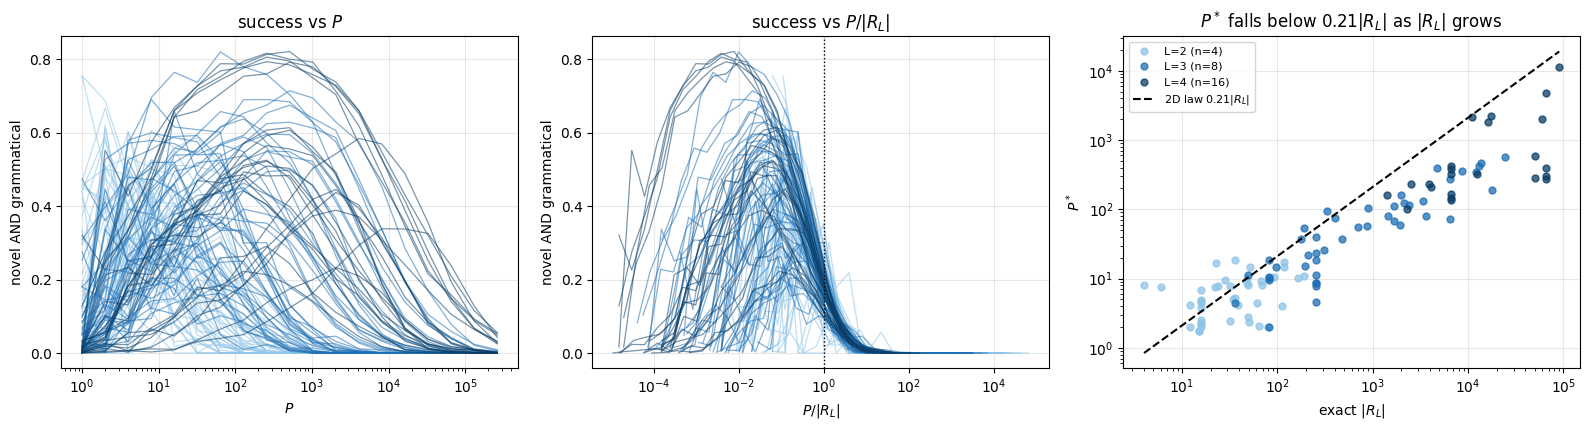

In [5]:
import matplotlib.pyplot as plt

cells = {}
for r in rows:
    cells.setdefault((r['v'], r['m'], r['s'], r['L'], r['rule_seed']), []).append(r)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for key, cs in cells.items():
    cs = sorted(cs, key=lambda r: r['P'])
    P = np.array([c['P'] for c in cs], float); S = np.array([c['success'] for c in cs], float)
    col = {2: '#8ec4e8', 3: '#1f6fb4', 4: '#0b3d66'}[key[3]]
    ax[0].plot(P, S, '-', lw=.9, color=col, alpha=.55)
    ax[1].plot(P / RL[key], S, '-', lw=.9, color=col, alpha=.55)
for a, t, xl in zip(ax[:2], ['success vs $P$', 'success vs $P/|R_L|$'],
                    ['$P$', '$P/|R_L|$']):
    a.set_xscale('log'); a.set_title(t); a.set_xlabel(xl); a.grid(alpha=.3)
    a.set_ylabel('novel AND grammatical')
ax[1].axvline(1.0, color='k', ls=':', lw=1)

for L, col in [(2, '#8ec4e8'), (3, '#1f6fb4'), (4, '#0b3d66')]:
    sel = [p for p in br if p['L'] == L]
    if not sel:
        continue
    R = np.array([p['R_L'] for p in sel], float); P = np.array([p['P_star'] for p in sel], float)
    ax[2].plot(R, P, 'o', ms=5, color=col, alpha=.75, label='L=%d (n=%d)' % (L, 2**L))
Rall = np.array([p['R_L'] for p in br], float)
ax[2].plot(np.sort(Rall), 0.21*np.sort(Rall), 'k--', lw=1.5, label='2D law $0.21|R_L|$')
ax[2].set_xscale('log'); ax[2].set_yscale('log'); ax[2].grid(alpha=.3)
ax[2].set_xlabel('exact $|R_L|$'); ax[2].set_ylabel('$P^*$'); ax[2].legend(fontsize=8)
ax[2].set_title('$P^*$ falls below $0.21|R_L|$ as $|R_L|$ grows')
fig.tight_layout()

## 5. Example traces

Three real generations at `v2 m2 L=3`, revealed one site at a time, at `P = 8` (near this
grammar's peak). `.` is a still-masked site; the posterior shown is over the `v = 2` symbols.

In [6]:
import torch
from scripts.rhm_1d_depth import RHM1D, LS1D, exact_RL, is_grammatical, MASK

dev = torch.device('cpu')
model = RHM1D(v=2, s=2, L=3, m=2, seed=1000)
k, d, P = 7, 8, 8
train = model.sample(P, seed=1234)
mach  = LS1D(train, model.v, k, dev, alpha_smooth=1e-3)
tr    = set(map(bytes, np.ascontiguousarray(train.astype(np.int8))))
print('|R_L| = %d exactly;  %d distinct training strings;  table = %d distinct windows'
      % (exact_RL(model), len(tr), mach.n_distinct))

g  = torch.Generator(device=dev).manual_seed(5)
xt = torch.full((3, d), MASK, dtype=torch.int64)
rowsT = torch.arange(3)
log = [[] for _ in range(3)]
for _ in range(d):
    masked = xt == MASK
    noise  = torch.rand(3, d, generator=g)
    pick   = torch.where(masked, noise, torch.full_like(noise, -1.)).argmax(1)
    p      = mach.posterior(xt, pick).clamp_min(1e-12)
    tok    = torch.multinomial(p, 1, generator=g)[:, 0]
    for b in range(3):
        log[b].append((''.join('.' if t < 0 else str(int(t)) for t in xt[b]),
                       int(pick[b]), p[b].numpy(), int(tok[b])))
    xt[rowsT, pick] = tok

for b in range(3):
    print('\n--- trace %d ---' % b)
    print('step  state     site  posterior      ->')
    for i, (st, si, pp, tk) in enumerate(log[b]):
        print('%2d    %s   %d     [%s]    %d' % (i, st, si, ' '.join('%.2f' % q for q in pp), tk))
    fin  = ''.join(str(int(t)) for t in xt[b])
    gram = bool(is_grammatical(model, xt[b:b+1].numpy())[0])
    nov  = bytes(np.ascontiguousarray(xt[b].numpy().astype(np.int8))) not in tr
    print('final %s  grammatical=%s  novel=%s  => %s'
          % (fin, gram, nov, 'SUCCESS' if (gram and nov) else 'no'))

|R_L| = 49 exactly;  8 distinct training strings;  table = 51 distinct windows

--- trace 0 ---
step  state     site  posterior      ->
 0    ........   4     [0.50 0.50]    1
 1    ....1...   3     [0.67 0.33]    0
 2    ...01...   5     [0.50 0.50]    1
 3    ...011..   7     [1.00 0.00]    0
 4    ...011.0   1     [0.50 0.50]    1
 5    .1.011.0   6     [0.50 0.50]    1
 6    .1.01110   0     [0.50 0.50]    0
 7    01.01110   2     [0.50 0.50]    1
final 01101110  grammatical=True  novel=True  => SUCCESS

--- trace 1 ---
step  state     site  posterior      ->
 0    ........   1     [0.00 1.00]    1
 1    .1......   2     [0.25 0.75]    1
 2    .11.....   4     [0.86 0.14]    1
 3    .11.1...   6     [0.00 1.00]    1
 4    .11.1.1.   7     [1.00 0.00]    0
 5    .11.1.10   0     [0.83 0.17]    0
 6    011.1.10   5     [1.00 0.00]    0
 7    011.1010   3     [0.00 1.00]    1
final 01111010  grammatical=True  novel=False  => no

--- trace 2 ---
step  state     site  posterior      ->


## 6. What this does and does not show

**Shows.**

* `P* = exp(Theta(n))` at three depths rather than two. Since `|R_L| = Theta(v m^((n-1)/(s-1)))`
  is itself exponential in `n`, any positive power of it is too -- so `b < 1` does not threaten
  the asymptotic statement, which is the deadline deliverable.
* The sharper 2D statement `P* = 0.21 |R_L|` is dimension-specific, with the matched-`n` control
  ruling out size as the explanation.

**Does not show.**

* *Why.* The coverage hypothesis -- that `x*` falls as one window covers more of the sample (at
  `n = 16`, `k/d = 94%` in 1D against `k^2/n = 56%` in 2D) -- is consistent with everything here,
  including 1D's much higher median peak success (0.49 vs 0.022), but is **untested**. The clean
  test is inside 2D alone: sweep `k` below the U=1 value and see whether `x*` tracks `k^2/n`. If
  it does, 1D and 2D are one law in coverage rather than two in dimension.
* Anything at `L >= 5` in 1D: `v2 m2` there would need `P* ~ 9e8`.
* Cells whose grammar exceeds `R_max = 1.5e5`, which the P ladder could not bracket. They are
  reported as skipped in the job log, never silently dropped.
* Three cells peaked at a ladder endpoint and are excluded; their `x*` is a bound, not a value.

**Method note.** Job 51009204 was OOM-killed at 64 GB *after* all 113 measurement cells had
finished, inside `exact_RL`, which held millions of Python `bytes` per symbol for grammars it was
about to skip anyway. The measurement path itself is flat in depth -- host RSS 0.99/1.02/1.06 GB
at `L = 2/3/4`, GPU peak 0.11/0.33/1.17 GB, matching the `P*d*k` window tensor. `exact_RL` is now
capped at 1e6 words checked in both loops, with a nominal pre-guard; the cells that killed the job
now run in 3.7 s at 0.69 GB.